# 2 — Distribuição das ASTs sorteadas

**Pergunta:** quais características estruturais aparecem quando o sorteador genérico do projeto gera árvores aleatórias com sua configuração padrão?

Este notebook amostra mecanismos com `sample_random_mechanisms` e resume tamanho, profundidade, tipos de folhas e operadores, atrasos e formas binárias. As distribuições descrevem o sorteador e a configuração registrados abaixo; não são uma amostra de mecanismos naturais nem uma avaliação de outros geradores, como o de contração.

A análise usa o `RandomTreeConfig` padrão sem modificações: 1–6 operadores, uma série, terminais `Parameter`/`Lag` com probabilidades 0,40/0,60, probabilidade de soma 0,65 e ao menos um lag por árvore. O número de operadores é sorteado uniformemente. Condicionalmente a esse número, a forma binária completa é amostrada com pesos de números de Catalan.

In [1]:
from pathlib import Path
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
sys.path.insert(0, str(root / "src"))

from tsfmxai.generators import (
    RandomTreeConfig,
    full_binary_tree_shape_count,
    sample_random_mechanisms,
)
from tsfmxai.representations import Add, Lag, Multiply, Parameter, walk

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [2]:
ROOT_SEED = 20261028
SAMPLE_COUNT = 10_000
CONFIG = RandomTreeConfig()

mechanisms = sample_random_mechanisms(
    CONFIG,
    root_seed=ROOT_SEED,
    count=SAMPLE_COUNT,
)

def binary_shape(node):
    """Return a topology fingerprint that ignores node and leaf labels."""
    if isinstance(node, (Add, Multiply)):
        return f"({binary_shape(node.left)},{binary_shape(node.right)})"
    return "."

def measure(mechanism):
    nodes = list(walk(mechanism.expression))
    operators = [node for node in nodes if isinstance(node, (Add, Multiply))]
    parameters = [node for node in nodes if isinstance(node, Parameter)]
    lags = [node for node in nodes if isinstance(node, Lag)]
    resolved_lags = [mechanism.binding.lag_values[node.slot] for node in lags]
    return {
        "sample_index": mechanism.sample_index,
        "operator_count": len(operators),
        "node_count": len(nodes),
        "tree_depth": max_depth(mechanism.expression),
        "add_count": sum(isinstance(node, Add) for node in operators),
        "multiply_count": sum(isinstance(node, Multiply) for node in operators),
        "parameter_count": len(parameters),
        "lag_count": len(lags),
        "distinct_lag_values": len(set(resolved_lags)),
        "minimum_lag": min(resolved_lags),
        "maximum_lag": max(resolved_lags),
        "shape": binary_shape(mechanism.expression),
    }

def max_depth(node):
    if isinstance(node, (Add, Multiply)):
        return 1 + max(max_depth(node.left), max_depth(node.right))
    return 1

df = pd.DataFrame.from_records(measure(mechanism) for mechanism in mechanisms)
assert len(df) == SAMPLE_COUNT
assert (df["lag_count"] >= 1).all()
assert (df["node_count"] == 2 * df["operator_count"] + 1).all()

print(f"Amostras: {len(df):,}")
print("Operadores por árvore:")
display(df["operator_count"].value_counts().sort_index().rename("contagem").to_frame())
print("Resumo das características:")
display(df[["operator_count", "node_count", "tree_depth", "parameter_count", "lag_count", "distinct_lag_values"]].describe().round(3))
print("Composição das folhas (contagem total):")
display(df[["parameter_count", "lag_count"]].sum().rename("contagem").to_frame())

Amostras: 10,000
Operadores por árvore:


,contagem
operator_count,
1,1672
2,1631
3,1684
4,1651
5,1737
6,1625


Resumo das características:


,operator_count,node_count,tree_depth,parameter_count,lag_count,distinct_lag_values
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,3.502,8.005,4.088,1.748,2.754,2.483
std,1.704,3.407,1.412,1.228,1.398,1.201
min,1.000,3.000,2.000,0.000,1.000,1.000
25%,2.000,5.000,3.000,1.000,2.000,2.000
50%,4.000,9.000,4.000,2.000,3.000,2.000
75%,5.000,11.000,5.000,3.000,4.000,3.000
max,6.000,13.000,7.000,6.000,7.000,7.000


Composição das folhas (contagem total):


,contagem
parameter_count,17482
lag_count,27543


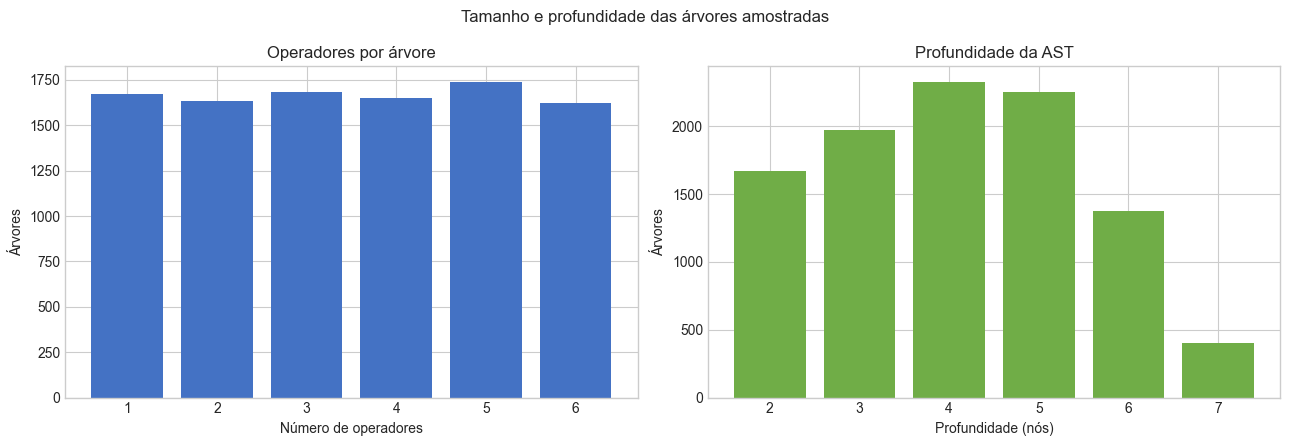

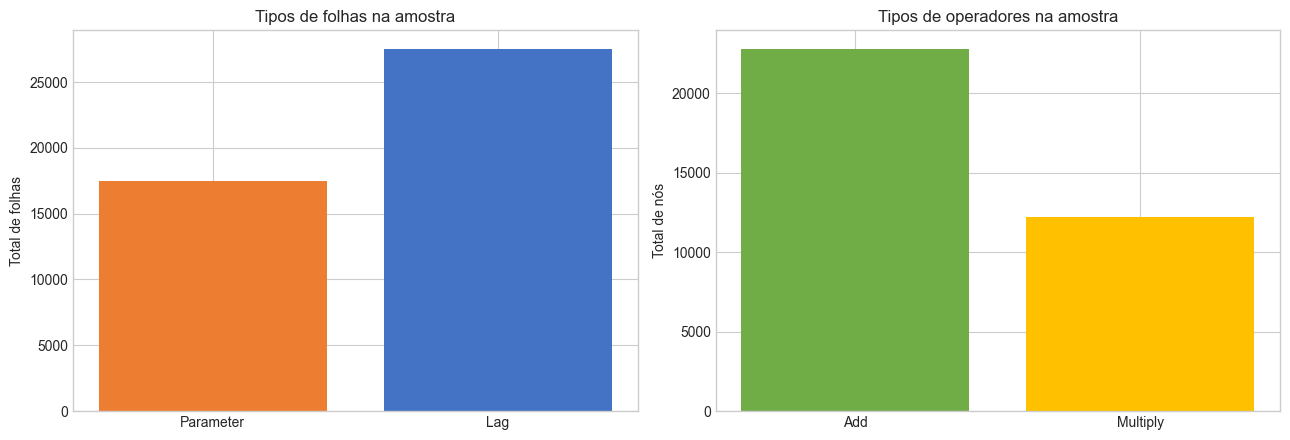

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

operator_counts = df["operator_count"].value_counts().sort_index()
axes[0].bar(operator_counts.index, operator_counts.values, color="#4472C4")
axes[0].set(title="Operadores por árvore", xlabel="Número de operadores", ylabel="Árvores")
axes[0].set_xticks(operator_counts.index)

depth_counts = df["tree_depth"].value_counts().sort_index()
axes[1].bar(depth_counts.index, depth_counts.values, color="#70AD47")
axes[1].set(title="Profundidade da AST", xlabel="Profundidade (nós)", ylabel="Árvores")
axes[1].set_xticks(depth_counts.index)

fig.suptitle("Tamanho e profundidade das árvores amostradas")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
leaf_totals = df[["parameter_count", "lag_count"]].sum()
axes[0].bar(["Parameter", "Lag"], leaf_totals.values, color=["#ED7D31", "#4472C4"])
axes[0].set(title="Tipos de folhas na amostra", ylabel="Total de folhas")

operator_totals = df[["add_count", "multiply_count"]].sum()
axes[1].bar(["Add", "Multiply"], operator_totals.values, color=["#70AD47", "#FFC000"])
axes[1].set(title="Tipos de operadores na amostra", ylabel="Total de nós")

fig.tight_layout()
plt.show()

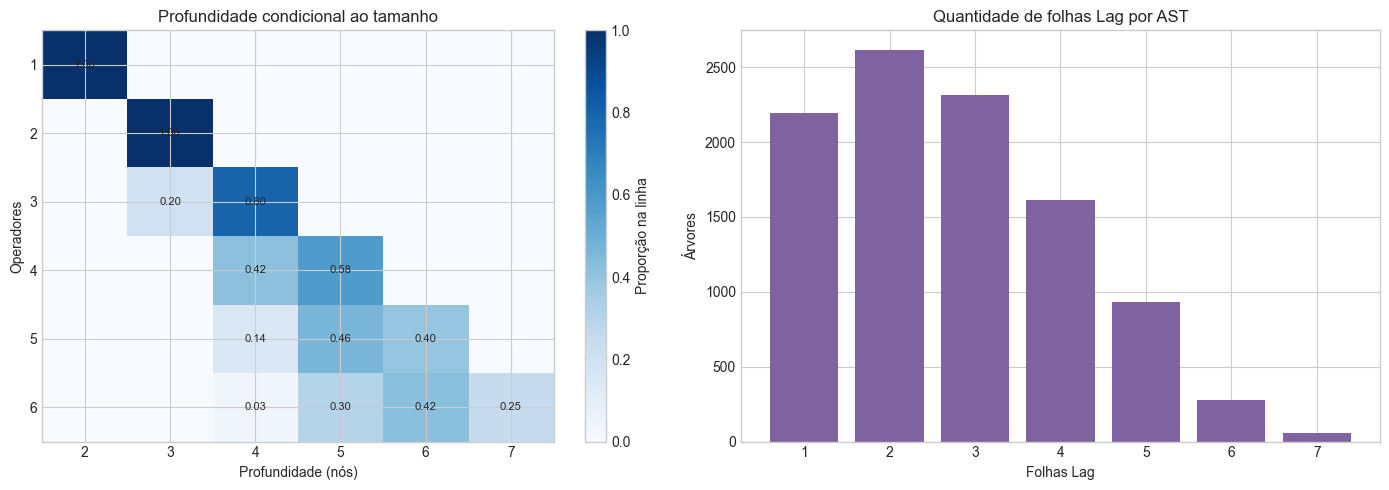

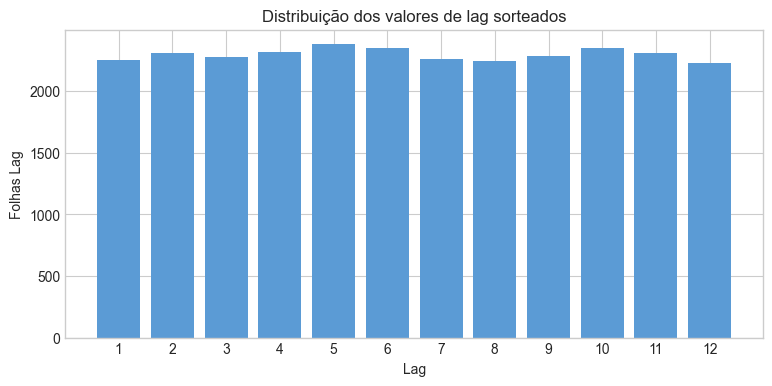

In [4]:
depth_by_size = pd.crosstab(df["operator_count"], df["tree_depth"], normalize="index")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
image = axes[0].imshow(depth_by_size.to_numpy(), aspect="auto", cmap="Blues", vmin=0)
axes[0].set(
    title="Profundidade condicional ao tamanho",
    xlabel="Profundidade (nós)",
    ylabel="Operadores",
    xticks=np.arange(len(depth_by_size.columns)),
    xticklabels=depth_by_size.columns,
    yticks=np.arange(len(depth_by_size.index)),
    yticklabels=depth_by_size.index,
)
for row in range(depth_by_size.shape[0]):
    for column in range(depth_by_size.shape[1]):
        value = depth_by_size.iloc[row, column]
        if value > 0:
            axes[0].text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=axes[0], label="Proporção na linha")

lag_counts = df["lag_count"].value_counts().sort_index()
axes[1].bar(lag_counts.index, lag_counts.values, color="#8064A2")
axes[1].set(title="Quantidade de folhas Lag por AST", xlabel="Folhas Lag", ylabel="Árvores")
axes[1].set_xticks(lag_counts.index)

fig.tight_layout()
plt.show()

lag_value_counts = pd.Series(
    [mechanism.binding.lag_values[node.slot]
     for mechanism in mechanisms
     for node in walk(mechanism.expression)
     if isinstance(node, Lag)]
).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(lag_value_counts.index, lag_value_counts.values, color="#5B9BD5")
ax.set(title="Distribuição dos valores de lag sorteados", xlabel="Lag", ylabel="Folhas Lag")
ax.set_xticks(range(CONFIG.minimum_lag, CONFIG.maximum_lag + 1))
plt.show()

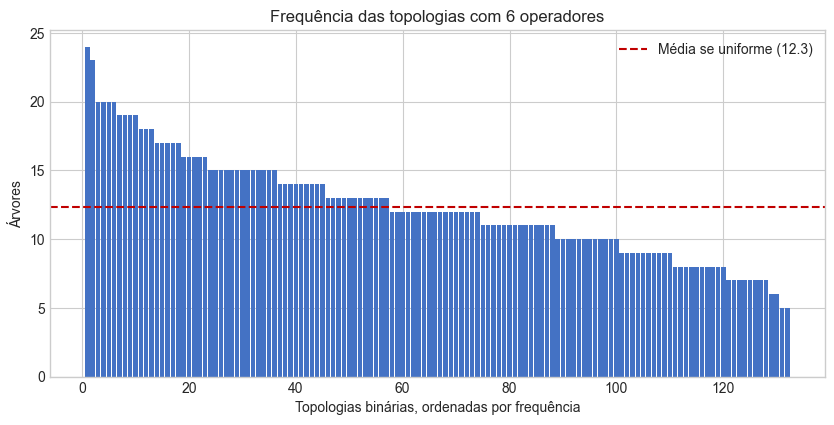

Árvores com 6 operadores: 1,625
Topologias binárias possíveis: 132 (número de Catalan)
Topologias distintas observadas: 132
Frequência média esperada por topologia sob uniformidade: 12.31


In [5]:
MAX_OPERATORS = CONFIG.maximum_operators
largest_trees = df.loc[df["operator_count"] == MAX_OPERATORS]
shape_counts = largest_trees["shape"].value_counts()
theoretical_shapes = full_binary_tree_shape_count(MAX_OPERATORS)
ranked_counts = shape_counts.reindex(shape_counts.sort_values(ascending=False).index).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(np.arange(1, len(ranked_counts) + 1), ranked_counts.values, color="#4472C4", width=0.85)
expected = len(largest_trees) / theoretical_shapes
ax.axhline(expected, color="#C00000", linestyle="--", label=f"Média se uniforme ({expected:.1f})")
ax.set(
    title=f"Frequência das topologias com {MAX_OPERATORS} operadores",
    xlabel="Topologias binárias, ordenadas por frequência",
    ylabel="Árvores",
)
ax.legend()
plt.show()

print(f"Árvores com {MAX_OPERATORS} operadores: {len(largest_trees):,}")
print(f"Topologias binárias possíveis: {theoretical_shapes:,} (número de Catalan)")
print(f"Topologias distintas observadas: {shape_counts.size:,}")
print(f"Frequência média esperada por topologia sob uniformidade: {expected:.2f}")

## Cobertura de skeletons, lags e fatores

Skeleton = lista ordenada de monômios cujo coeficiente final é não nulo. Duas ASTs distintas podem gerar o mesmo skeleton. Com 12 lags e grau máximo quatro, há C(16,4)=1.820 monômios possíveis (inclusive a constante), portanto 2^1.820 skeletons matemáticos. Essa contagem inclui expressões fora do alcance do sorteador atual. Com no máximo seis operadores binários, uma AST tem até sete folhas e pode produzir no máximo 12 termos antes de agrupar; calculamos um limite superior mais restrito e, em seguida, contamos os skeletons efetivamente observados em prefixos de 50.000 gerações com a configuração padrão e a mesma sequência de seeds. Fator significa uma ocorrência de lag em um termo, inclusive quando o mesmo lag aparece repetido.

In [6]:
from collections import Counter
from math import comb, log10
from tsfmxai.generators import derive_sample_seed, sample_random_mechanism
from tsfmxai.representations import canonicalize_polynomial

LAG_COUNT = CONFIG.maximum_lag - CONFIG.minimum_lag + 1
assert CONFIG.num_series == 1 and LAG_COUNT == 12
MAX_DEGREE = 4
POSSIBLE_MONOMIALS = comb(LAG_COUNT + MAX_DEGREE, MAX_DEGREE)
ALL_SUBSETS = 1 << POSSIBLE_MONOMIALS

# Com n folhas, o máximo de termos antes de agrupá-los vem de
# soma (T_i + T_j) ou produto (T_i * T_j) de duas subárvores.
max_terms = {1: 1}
for leaves in range(2, CONFIG.maximum_operators + 2):
    max_terms[leaves] = max(
        max(max_terms[left] + max_terms[leaves-left],
            max_terms[left] * max_terms[leaves-left])
        for left in range(1, leaves))
MAX_LEAVES = CONFIG.maximum_operators + 1
MAX_TERMS = max_terms[MAX_LEAVES]
assert (MAX_LEAVES, MAX_TERMS) == (7, 12)

def monomial_count(n):
    return comb(n + MAX_DEGREE, MAX_DEGREE)

def limited_support_count(n):
    return sum(comb(monomial_count(n), size)
               for size in range(min(MAX_TERMS, monomial_count(n)) + 1))

# Inclusão-exclusão: suportes com exatamente r lags distintos.
def exact_r_lags(r):
    return sum((-1)**(r-j) * comb(r, j) * limited_support_count(j)
               for j in range(r + 1))

CANDIDATE_BOUND = sum(comb(LAG_COUNT, r) * exact_r_lags(r)
                      for r in range(MAX_LEAVES + 1))
assert CANDIDATE_BOUND < ALL_SUBSETS
display(pd.DataFrame([
    {'Espaço': 'Todos os subconjuntos dos 1.820 monômios',
     'Quantidade': f'2^{POSSIBLE_MONOMIALS}', 'Interpretação': 'Universo matemático'},
    {'Espaço': 'Até 7 lags distintos e 12 termos',
     'Quantidade': str(CANDIDATE_BOUND), 'Interpretação': 'Limite superior do sorteador'}
]))
print('Máximo de termos para 1..7 folhas:', max_terms)
print('Ordem de grandeza do universo: 10^%.1f; do limite: 10^%.1f'
      % (POSSIBLE_MONOMIALS * log10(2), log10(CANDIDATE_BOUND)))

,Espaço,Quantidade,Interpretação
0,Todos os subconjuntos dos 1.820 monômios,2^1820,Universo matemático
1,Até 7 lags distintos e 12 termos,2285729108364834065947672,Limite superior do sorteador


Máximo de termos para 1..7 folhas: {1: 1, 2: 2, 3: 3, 4: 4, 5: 6, 6: 9, 7: 12}
Ordem de grandeza do universo: 10^547.9; do limite: 10^24.4


O primeiro número conta todos os subconjuntos do dicionário de monômios. O segundo conta exatamente os subconjuntos que satisfazem as duas condições necessárias calculadas acima; ainda pode incluir skeletons impossíveis de obter com apenas seis operações. Por isso, a cobertura do sorteador não é apresentada como uma porcentagem desse limite.

In [7]:
COVERAGE_COUNT = 50_000
CHECKPOINTS = (100, 500, 1_000, 5_000, 10_000, 20_000, 50_000)
seen = set()
skeleton_counts = Counter()
seen_terms = {degree: set() for degree in range(5)}
lag_leaves = Counter()
lag_support = Counter()
term_occurrences = Counter()
trees_with_degree = Counter()
operator_counts = Counter()
degree_rejected = accepted = 0
rows = []
previous_distinct = 0
prefix_check = None
for index in range(COVERAGE_COUNT):
    mechanism = sample_random_mechanism(
        CONFIG, seed=derive_sample_seed(ROOT_SEED, index), sample_index=index)
    nodes = list(walk(mechanism.expression))
    operator_counts[len(nodes)//2] += 1
    for node in nodes:
        if isinstance(node, Lag):
            lag_leaves[mechanism.binding.lag_values[node.slot]] += 1
    try:
        normal = canonicalize_polynomial(mechanism.expression, mechanism.binding)
    except ValueError as error:
        assert 'degree' in str(error), (index, str(error))
        degree_rejected += 1
    else:
        accepted += 1
        seen.add(normal.skeleton)
        skeleton_counts[normal.skeleton] += 1
        degrees = set()
        lags = set()
        for term in normal.skeleton:
            degree = len(term)
            degrees.add(degree)
            seen_terms[degree].add(term)
            term_occurrences[degree] += 1
            lags.update(lag for _, lag in term)
        trees_with_degree.update(degrees)
        lag_support.update(lags)
    count = index + 1
    if count == SAMPLE_COUNT:
        prefix_check = (operator_counts.copy(), lag_leaves.copy())
    if count in CHECKPOINTS:
        distinct = len(seen)
        rows.append({
            'Gerações x': count, 'Convertidas em skeletons': accepted, 'Rejeitadas por grau': degree_rejected,
            'Skeletons diferentes': distinct,
            'Novos no intervalo': distinct - previous_distinct,
            'Lags presentes': sum(lag_support[lag] > 0 for lag in range(1, 13)),
        })
        previous_distinct = distinct
assert prefix_check[0] == Counter(df['operator_count'])
assert sum(prefix_check[1].values()) == int(df['lag_count'].sum())
assert accepted + degree_rejected == COVERAGE_COUNT
assert sum(skeleton_counts.values()) == accepted
assert len(skeleton_counts) == len(seen)
coverage_df = pd.DataFrame(rows)
display(coverage_df)
print('Observados:', len(seen), '| limite superior:', CANDIDATE_BOUND)

,Gerações x,Convertidas em skeletons,Rejeitadas por grau,Skeletons diferentes,Novos no intervalo,Lags presentes
0,100,100,0,92,92,12
1,500,497,3,376,284,12
2,1000,997,3,679,303,12
3,5000,4986,14,2606,1927,12
4,10000,9971,29,4646,2040,12
5,20000,19940,60,8162,3516,12
6,50000,49838,162,17101,8939,12


Observados: 17101 | limite superior: 2285729108364834065947672


Cada valor de x é um prefixo da mesma sequência de seeds. A checagem do prefixo de 10.000 reproduz as contagens anteriores do notebook. Árvores cujo grau excede quatro aparecem separadamente; as demais entram na contagem de skeletons distintos.

In [8]:
lag_df = pd.DataFrame([{
    'Lag': lag,
    'Folhas sorteadas (todas as ASTs)': lag_leaves[lag],
    'ASTs convertidas que usam o lag': lag_support[lag],
    'ASTs convertidas que usam o lag (%)': 100 * lag_support[lag] / accepted,
} for lag in range(1, 13)])
assert (lag_df['Folhas sorteadas (todas as ASTs)'] > 0).all()

factor_rows = []
for degree in range(5):
    possible = 1 if degree == 0 else comb(LAG_COUNT+degree-1, degree)
    observed = seen_terms[degree]
    possible_repeated = 0 if degree < 2 else possible - comb(LAG_COUNT, degree)
    observed_repeated = sum(len(set(term)) < degree for term in observed)
    factor_rows.append({
        'Fatores de lag por termo': degree,
        'Monômios possíveis': possible,
        'Monômios observados': len(observed),
        'Cobertura (%)': 100 * len(observed) / possible,
        'Com lag repetido possíveis': possible_repeated,
        'Com lag repetido observados': observed_repeated,
        'Ocorrências nos skeletons': term_occurrences[degree],
        'Árvores aceitas com esse grau': trees_with_degree[degree],
    })
factor_df = pd.DataFrame(factor_rows)
assert factor_df['Monômios possíveis'].sum() == POSSIBLE_MONOMIALS
display(lag_df)
display(factor_df)

,Lag,Folhas sorteadas (todas as ASTs),ASTs convertidas que usam o lag,ASTs convertidas que usam o lag (%)
0,1,11351,10245,20.556603
1,2,11525,10367,20.801397
2,3,11587,10387,20.841527
3,4,11555,10350,20.767286
4,5,11604,10453,20.973956
5,6,11614,10423,20.913761
6,7,11337,10202,20.470324
7,8,11190,10106,20.277700
8,9,11563,10334,20.735182
9,10,11443,10288,20.642883


,Fatores de lag por termo,Monômios possíveis,Monômios observados,Cobertura (%),Com lag repetido possíveis,Com lag repetido observados,Ocorrências nos skeletons,Árvores aceitas com esse grau
0,0,1,1,100.000000,0,0,26009,26009
1,1,12,12,100.000000,0,0,75312,41977
2,2,78,78,100.000000,12,12,30522,19615
3,3,364,364,100.000000,144,144,8492,5749
4,4,1365,811,59.413919,870,415,1411,1041


A tabela de lags separa presença como folha sorteada da presença no skeleton final, com denominadores diferentes. A tabela de fatores conta todos os monômios possíveis de cada grau e quantos apareceram pelo menos uma vez. O mesmo lag pode aparecer duas ou mais vezes em um produto; essas combinações estão nas colunas de repetição.

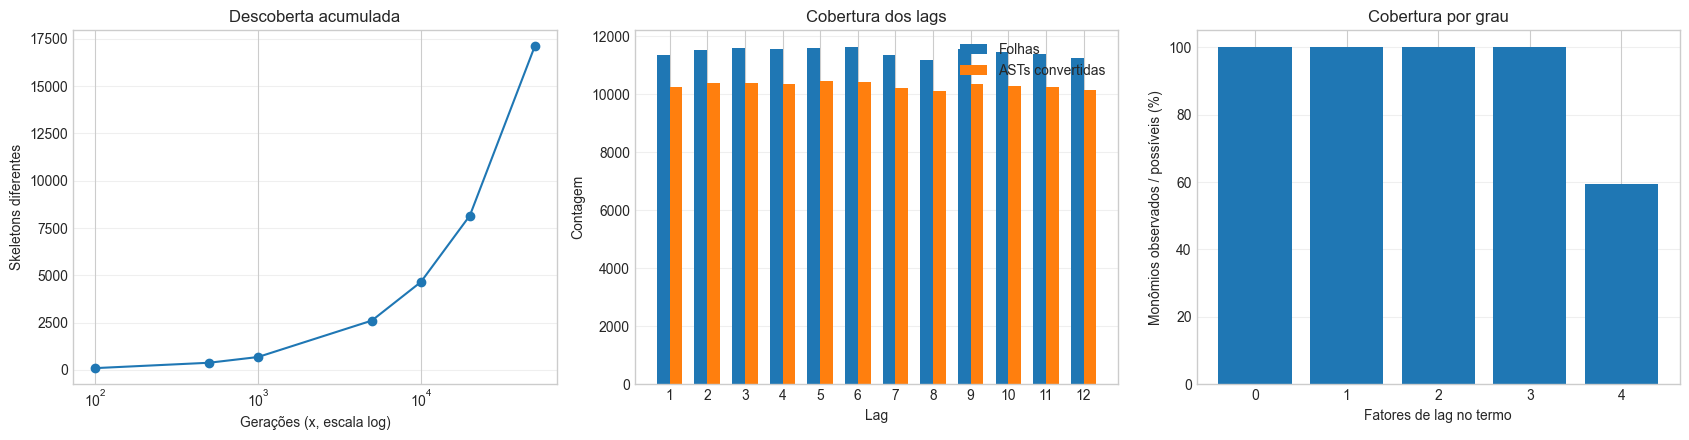

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(coverage_df['Gerações x'], coverage_df['Skeletons diferentes'], marker='o')
axes[0].set(xscale='log', xlabel='Gerações (x, escala log)',
            ylabel='Skeletons diferentes', title='Descoberta acumulada')
axes[1].bar(lag_df['Lag']-.17, lag_df['Folhas sorteadas (todas as ASTs)'],
            width=.34, label='Folhas')
axes[1].bar(lag_df['Lag']+.17, lag_df['ASTs convertidas que usam o lag'],
            width=.34, label='ASTs convertidas')
axes[1].set(xlabel='Lag', ylabel='Contagem', title='Cobertura dos lags')
axes[1].set_xticks(lag_df['Lag'])
axes[1].legend()
axes[2].bar(factor_df['Fatores de lag por termo'], factor_df['Cobertura (%)'])
axes[2].set(xlabel='Fatores de lag no termo', ylabel='Monômios observados / possíveis (%)',
            title='Cobertura por grau', ylim=(0, 105))
axes[2].set_xticks(range(5))
for axis in axes: axis.grid(axis='y', alpha=.3)
fig.tight_layout()
plt.show()

O primeiro gráfico acompanha skeletons novos; o segundo mostra a cobertura marginal de cada atraso; o terceiro revela quantas combinações de fatores apareceram em cada grau. O percentual do terceiro gráfico usa o dicionário matemático de monômios como denominador, e não o número desconhecido de skeletons alcançáveis pelo sorteador.

## Skeletons mais frequentes

A frequ?ncia abaixo conta **?rvores convertidas** que resultaram em cada skeleton, entre os mesmos 50.000 sorteios. A f?rmula mostra somente os termos presentes: `1` indica a presen?a de uma constante, e os coeficientes de todos os termos s?o omitidos. Assim, `x_0(t-1)` e `2x_0(t-1)` pertencem ao mesmo skeleton. O percentual usa as ?rvores convertidas como denominador.

In [10]:
def skeleton_formula(skeleton):
    if not skeleton:
        return '0'
    terms = []
    for monomial in skeleton:
        if not monomial:
            terms.append('1')
            continue
        multiplicities = Counter(monomial)
        factors = [
            f'x_{series}(t-{lag})' + (f'^{power}' if power > 1 else '')
            for (series, lag), power in sorted(multiplicities.items())
        ]
        terms.append(' ? '.join(factors))
    return ' + '.join(terms)

TOP_N = 15
ranked = sorted(skeleton_counts.items(), key=lambda item: (-item[1], item[0]))[:TOP_N]
most_frequent_df = pd.DataFrame([
    {
        'Posi??o': rank,
        'F?rmula do skeleton (sem coeficientes)': skeleton_formula(skeleton),
        '?rvores convertidas': count,
        'Frequ?ncia entre convertidas (%)': 100 * count / accepted,
        'Termos': len(skeleton),
        'Grau m?ximo': max((len(term) for term in skeleton), default=0),
    }
    for rank, (skeleton, count) in enumerate(ranked, start=1)
])
most_frequent_df['Frequ?ncia acumulada (%)'] = (
    100 * most_frequent_df['?rvores convertidas'].cumsum() / accepted
)
assert most_frequent_df['?rvores convertidas'].is_monotonic_decreasing
assert most_frequent_df['?rvores convertidas'].sum() <= accepted
assert most_frequent_df['F?rmula do skeleton (sem coeficientes)'].is_unique
display(most_frequent_df)
print('Skeletons observados uma ?nica vez:', sum(count == 1 for count in skeleton_counts.values()))
print(f'Participa??o dos {TOP_N} mais frequentes: {most_frequent_df["Frequ?ncia acumulada (%)"].iloc[-1]:.2f}%')

,Posi??o,F?rmula do skeleton (sem coeficientes),?rvores convertidas,Frequ?ncia entre convertidas (%),Termos,Grau m?ximo,Frequ?ncia acumulada (%)
0,1,1 + x_0(t-6),780,1.565071,2,1,1.565071
1,2,1 + x_0(t-4),761,1.526947,2,1,3.092018
2,3,1 + x_0(t-10),754,1.512902,2,1,4.604920
3,4,1 + x_0(t-5),734,1.472772,2,1,6.077692
4,5,1 + x_0(t-3),732,1.468759,2,1,7.546450
5,6,1 + x_0(t-11),732,1.468759,2,1,9.015209
6,7,1 + x_0(t-12),728,1.460733,2,1,10.475942
7,8,1 + x_0(t-1),715,1.434648,2,1,11.910590
8,9,1 + x_0(t-2),709,1.422609,2,1,13.333200
9,10,1 + x_0(t-9),709,1.422609,2,1,14.755809


Skeletons observados uma ?nica vez: 13827
Participa??o dos 15 mais frequentes: 19.13%


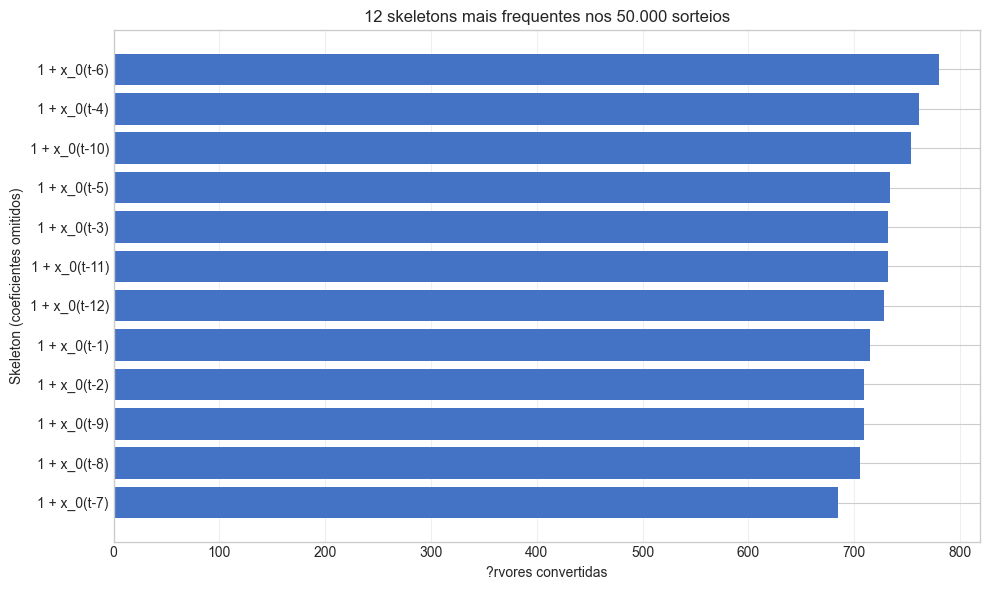

In [11]:
top_plot = most_frequent_df.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_plot['F?rmula do skeleton (sem coeficientes)'],
        top_plot['?rvores convertidas'], color='#4472C4')
ax.set(xlabel='?rvores convertidas',
       ylabel='Skeleton (coeficientes omitidos)',
       title='12 skeletons mais frequentes nos 50.000 sorteios')
ax.grid(axis='x', alpha=.3)
fig.tight_layout()
plt.show()

A tabela permite ler as f?rmulas completas dos padr?es mais comuns; o gr?fico destaca a diferen?a entre suas contagens. Frequ?ncia alta significa que o **sorteador** produz aquele conjunto de termos com frequ?ncia alta nesta configura??o. A diversidade total inclui tamb?m os skeletons que apareceram apenas uma vez.

In [12]:
# Registro do experimento
record = {
    "pergunta": "Quais características estruturais aparecem no sorteador genérico de ASTs sob sua configuração padrão?",
    "hipotese": "O tamanho terá frequências aproximadamente uniformes entre 1 e 6; a topologia binária será amostrada de modo aproximadamente uniforme condicionalmente ao tamanho; cada árvore terá ao menos um Lag.",
    "configuracao_completa": {
        "sampler": "sample_random_mechanisms",
        "RandomTreeConfig": CONFIG.__dict__,
        "sample_count": SAMPLE_COUNT,
        "root_seed": ROOT_SEED,
        "seed_derivation": "numpy SeedSequence([root_seed, sample_index]) via derive_sample_seed",
        "sample_indices": [0, SAMPLE_COUNT - 1],
        "tree_shape_definition": "forma binária completa ignorando rótulos dos nós e folhas",
    },
    "proveniencia": {
        "implementation": "src/tsfmxai/generators/random_expression.py",
        "representation": "src/tsfmxai/representations/expression.py",
        "notebook": "experiments/canonicalization/2_random_ast_distribution.ipynb",
        "sampling_unit": "uma AST e seu MechanismBinding por índice",
        "environment": {
            "python": platform.python_version(),
            "platform": platform.platform(),
            "numpy": np.__version__,
            "pandas": pd.__version__,
            "matplotlib": matplotlib.__version__,
        },
        "external_data": "nenhum",
        "limitations": "configuração genérica padrão; univariada; amostragem empírica finita; não representa geradores especializados",
    },
    "metricas_observadas": {
        "operator_count": df["operator_count"].value_counts().sort_index().to_dict(),
        "mean_depth": float(df["tree_depth"].mean()),
        "mean_leaf_counts": {key: int(value) for key, value in df[["parameter_count", "lag_count"]].sum().items()},
        "largest_tree_sample_count": int(len(largest_trees)),
        "binary_topologies_possible_at_max_size": int(theoretical_shapes),
        "binary_topologies_observed_at_max_size": int(shape_counts.size),
        "mean_frequency_per_possible_max_size_topology": float(expected),
    },
    "resumo_cientifico": (
        f"Na amostra, as contagens por tamanho foram {df['operator_count'].value_counts().sort_index().to_dict()}; "
        f"a profundidade média foi {df['tree_depth'].mean():.3f}. "
        f"Entre árvores de tamanho máximo, foram observadas {shape_counts.size} de {theoretical_shapes} topologias binárias possíveis. "
        "Esses números descrevem esta configuração e semente; diferenças em relação às proporções teóricas podem refletir variação amostral."
    ),
    "reproducao": "A partir da raiz do repositório: .\\.venv\\Scripts\\python.exe -m jupyter nbconvert --to notebook --execute --inplace experiments/canonicalization/2_random_ast_distribution.ipynb",
}
record["hipotese"] += " A cobertura de combinações de fatores deve cair para graus maiores."
record["configuracao_completa"]["coverage_extension"] = {
    "generation_count": COVERAGE_COUNT,
    "checkpoints": CHECKPOINTS,
    "same_root_seed_and_prefix": True,
    "max_polynomial_degree": MAX_DEGREE,
    "skeleton": "monômios ordenados com coeficiente realizado diferente de zero",
    "factor": "uma ocorrência de lag em um monômio, com repetição permitida",
}
record["proveniencia"]["canonicalizer"] = "src/tsfmxai/representations/canonical_polynomial.py"
record["metricas_observadas"]["coverage"] = {
    "possible_monomials": POSSIBLE_MONOMIALS,
    "unrestricted_skeletons": f"2^{POSSIBLE_MONOMIALS}",
    "candidate_upper_bound": CANDIDATE_BOUND,
    "checkpoints": coverage_df.to_dict(orient="records"),
    "accepted": accepted,
    "degree_rejected": degree_rejected,
    "lag_coverage": lag_df.to_dict(orient="records"),
    "factor_coverage": factor_df.to_dict(orient="records"),
    "top_skeletons": most_frequent_df.to_dict(orient="records"),
    "singleton_skeletons": sum(count == 1 for count in skeleton_counts.values()),
}
record["resumo_cientifico"] += (
    f" Na extensão de {COVERAGE_COUNT} gerações, {accepted} árvores foram canonizadas, "
    f"{len(seen)} skeletons distintos apareceram e "
    f"{degree_rejected} ultrapassaram grau quatro. O limite superior combinatório "
    f"calculado é {CANDIDATE_BOUND}; ele não é a contagem exata de skeletons "
    "alcançáveis pelo sorteador. As tabelas acima separam cobertura de lags e de fatores."
)
from pprint import pprint
pprint(record, sort_dicts=False)

{'pergunta': 'Quais características estruturais aparecem no sorteador genérico '
             'de ASTs sob sua configuração padrão?',
 'hipotese': 'O tamanho terá frequências aproximadamente uniformes entre 1 e '
             '6; a topologia binária será amostrada de modo aproximadamente '
             'uniforme condicionalmente ao tamanho; cada árvore terá ao menos '
             'um Lag. A cobertura de combinações de fatores deve cair para '
             'graus maiores.',
 'configuracao_completa': {'sampler': 'sample_random_mechanisms',
                           'RandomTreeConfig': {'minimum_operators': 1,
                                                'maximum_operators': 6,
                                                'num_series': 1,
                                                'minimum_lag': 1,
                                                'maximum_lag': 12,
                                                'parameter_probability': 0.4,
                                   